<a href="https://colab.research.google.com/github/sabriddinovna/graph_nn/blob/main/GAT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import os
os.environ['TORCH']=torch.__version__
print(torch.__version__)

2.11.0+cpu


In [ ]:
!pip install -q torch-scatter -f https://data.pyg.org/whl/torch-${TORCH}.html
!pip install -q torch-sparse -f https://data.pyg.org/whl/torch-${TORCH}.html
!pip install -q git+https://github.com/pyg-team/pytorch_geometric.git
!pip install -q captum

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 682.1/682.1 kB 3.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 5.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 8.7 MB/s eta 0:00:00


In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt

This dataset consists of 4337 molecule graphs where the task is to predict the molecule mutagenicity.

In [ ]:
from torch_geometric.loader import DataLoader
from torch_geometric.datasets import TUDataset

In [ ]:
path='.'
dataset=TUDataset(path,name='Mutagenicity').shuffle()
test_data=dataset[ : len(dataset) // 10]
train_data=dataset[len(dataset) // 10 : ]

test_loader=DataLoader(test_data, batch_size=128)
train_loader=DataLoader(train_data, batch_size=128)

Processing...
Done!


In [ ]:
import networkx as nx
import numpy as np

In [ ]:
from torch_geometric.utils import to_networkx

In [ ]:
def draw_molecule(g, edge_mask=None, draw_edge_labels=False):
    g = g.copy().to_undirected()
    node_labels = {}
    for u, data in g.nodes(data=True):
        node_labels[u] = data['name']
    pos = nx.planar_layout(g)
    pos = nx.spring_layout(g, pos=pos)
    if edge_mask is None:
        edge_color = 'black'
        widths = None
    else:
        edge_color = [edge_mask[(u, v)] for u, v in g.edges()]
        widths = [x * 10 for x in edge_color]
    nx.draw(g, pos=pos, labels=node_labels, width=widths,
            edge_color=edge_color, edge_cmap=plt.cm.Blues,
            node_color='azure')

    if draw_edge_labels and edge_mask is not None:
        edge_labels = {k: ('%.2f' % v) for k, v in edge_mask.items()}
        nx.draw_networkx_edge_labels(g, pos, edge_labels=edge_labels,
                                    font_color='red')
    plt.show()


def to_molecule(data):
    ATOM_MAP = ['C', 'O', 'Cl', 'H', 'N', 'F',
                'Br', 'S', 'P', 'I', 'Na', 'K', 'Li', 'Ca']
    g = to_networkx(data, node_attrs=['x'])
    for u, data in g.nodes(data=True):
        data['name'] = ATOM_MAP[data['x'].index(1.0)]
        del data['x']
    return g


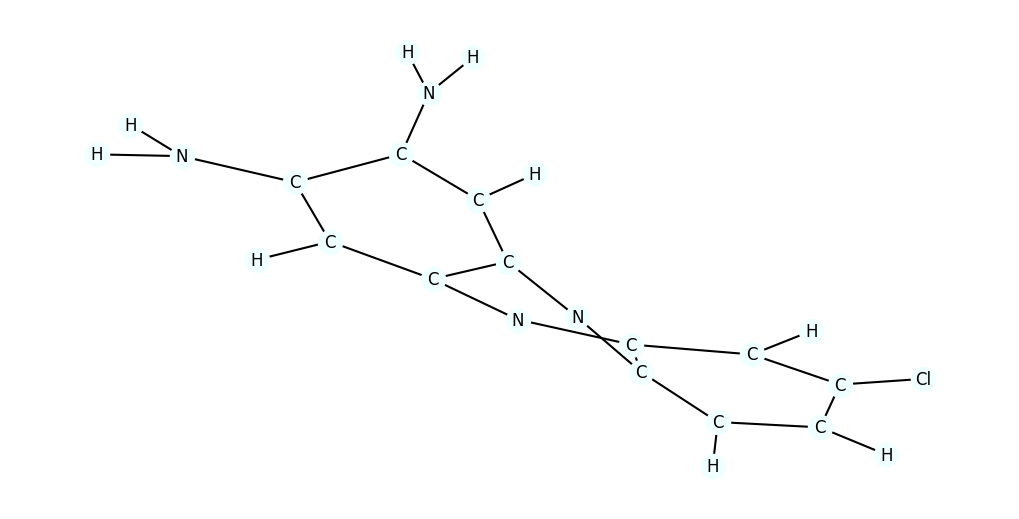

In [ ]:
import random

data = random.choice([t for t in train_data])
mol = to_molecule(data)
plt.figure(figsize=(10, 5))
draw_molecule(mol)

In [ ]:
import torch
import os
os.environ['TORCH']=torch.__version__

In [ ]:

!pip install -q torch-scatter -f https://data.pyg.org/whl/torch-${TORCH}.html
!pip install -q torch-sparse -f https://data.pyg.org/whl/torch-${TORCH}.html
!pip install -q git+https://github.com/pyg-team/pytorch_geometric.git

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
from torch_geometric.datasets import TUDataset
if 'IS_GRADESCOPE_ENV' not in os.environ:
  root = './enzymes'
  name = 'ENZYMES'

  # The ENZYMES dataset
  pyg_dataset= TUDataset(root, name)

  # You will find that there are 600 graphs in this dataset
  print(pyg_dataset)

In [ ]:
# Original interface with string type as aggregation argument
class MyConv(MessagePassing):
    def __init__(self):
        super().__init__(aggr="mean")


# Use a single aggregation module as aggregation argument
class MyConv(MessagePassing):
    def __init__(self):
        super().__init__(aggr=MeanAggregation())


# Use a list of aggregation strings as aggregation argument
class MyConv(MessagePassing):
    def __init__(self):
        super().__init__(aggr=['mean', 'max', 'sum', 'std', 'var'])


# Use a list of aggregation modules as aggregation argument
class MyConv(MessagePassing):
    def __init__(self):
        super().__init__(aggr=[
            MeanAggregation(),
            MaxAggregation(),
            SumAggregation(),
            StdAggregation(),
            VarAggregation(),
        ])


# Use a list of mixed modules and strings as aggregation argument
class MyConv(MessagePassing):
    def __init__(self):
        super().__init__(aggr=[
            'mean',
            MaxAggregation(),
            'sum',
            StdAggregation(),
            'var',
        ])


# Define multiple aggregations with `MultiAggregation` module
class MyConv(MessagePassing):
    def __init__(self):
        super().__init__(aggr=MultiAggregation([
            SoftmaxAggregation(t=0.1, learn=True),
            SoftmaxAggregation(t=1, learn=True),
            SoftmaxAggregation(t=10, learn=True)
        ]))



NameError: name 'MessagePassing' is not defined

In [ ]:
import torch
from torch_geometric.datasets import Planetoid
from torch_geometric.transforms import NormalizeFeatures

ModuleNotFoundError: No module named 'torch_geometric'

In [ ]:
dataset=Planetoid(root='data/Planetoid', name='PubMed', transform=NormalizeFeatures())


Processing...
Done!


In [ ]:
len(dataset)

1

In [ ]:
data=dataset[0]

In [ ]:
from torch_geometric.loader import ClusterData, ClusterLoader
seed=42
torch.manual_seed(seed)
cluster_data = ClusterData(data, num_parts=128)  # 1. Create subgraphs.
train_loader = ClusterLoader(cluster_data, batch_size=32,
                             shuffle=True)  # 2. Stochastic partioning scheme.

Computing METIS partitioning...
Done!


In [ ]:
criterion=torch.nn.CrossEntropyLoss()

In [ ]:
def train(model):
  model.train()
  optimizer=torch.optim.Adam(model.parameters(),  lr=0.01, weight_decay=5e-4)

  for sub_data in train_loader:
    optimizer.zero_grad()
    out=model(sub_data.x, sub_data.edge_index)
    loss=criterion(out[sub_data.train_mask], sub_data.y[sub_data.train_mask])
    loss.backward()
    optimizer.step()

def test(model):
  model.eval()
  out=model(data.x, data.edge_index)
  pred=out.argmax(dim=1)

  accs=[]
  for mask in  [data.train_mask,data.val_mask, data.test_mask]:
    correct=pred[mask]==data.y[mask]
    accs.append(int(correct.sum())/int(mask.sum()))


  return accs

def run(model, epochs=5):
  loss=train(model)
  train_acc, val_acc, test_acc=test(model)
  print(
            f'Epoch: {epoch:03d}, Train: {train_acc:.4f}, Val Acc: {val_acc:.4f}, Test Acc: {test_acc:.4f}'
        )

In [ ]:
import copy
import torch.nn.functional as F
from torch_geometric.nn import (
    Aggregation,
    MaxAggregation,
    MeanAggregation,
    MultiAggregation,
    SAGEConv,
    SoftmaxAggregation,
    StdAggregation,
    SumAggregation,
    VarAggregation,
)

In [ ]:
class GNN(torch.nn.Module):
  def __init__(self, hidden_channels, aggr='mean', aggr_kwards=None):
    super().__init__()
    self.conv1=SAGECONV(
        dataset.num_node_features,
        hidden_channels,
        aggr=aggr,
        aggr_kwargs=aggr_kwargs,
    )

    self.conv2=SAGEConv(
        hidden_channels,
        dataset.num_classes,
        aggr=copy.deepcopy(aggr),
        aggr_kwargs=aggr_kwargs,
    )

  def forward(self, x, edge_index):
    x=self.conv1(x, edge_index)
    x=x.relu()
    x=F.dropout(x, p=0.5, training=self.training)
    x=self.conv2(x, edge_index)

    return x



NameError: name 'torch' is not defined

In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib import colors
plt.rcParams.update({'font.size': 16})

In [ ]:
x=torch.rand(20, 5)
x

tensor([[0.8369, 0.9623, 0.0572, 0.1477, 0.7773],
        [0.9037, 0.8899, 0.8205, 0.5369, 0.5966],
        [0.8306, 0.5949, 0.1135, 0.6676, 0.7805],
        [0.4325, 0.7862, 0.1654, 0.5203, 0.0633],
        [0.6752, 0.6484, 0.0286, 0.7832, 0.5166],
        [0.9454, 0.3513, 0.2097, 0.7670, 0.3921],
        [0.3358, 0.2157, 0.1090, 0.3695, 0.2113],
        [0.6099, 0.9005, 0.7342, 0.9227, 0.1092],
        [0.3997, 0.6351, 0.0516, 0.3359, 0.2887],
        [0.1568, 0.8027, 0.7540, 0.0903, 0.0059],
        [0.7457, 0.8328, 0.5881, 0.4133, 0.9127],
        [0.1787, 0.4627, 0.9140, 0.6887, 0.8280],
        [0.7998, 0.4610, 0.5069, 0.6336, 0.9115],
        [0.6222, 0.4654, 0.8742, 0.3069, 0.7758],
        [0.8365, 0.5018, 0.6503, 0.5433, 0.5283],
        [0.6357, 0.5169, 0.0918, 0.7789, 0.0739],
        [0.6993, 0.3361, 0.8812, 0.9785, 0.2247],
        [0.0508, 0.3222, 0.5049, 0.0638, 0.0995],
        [0.4062, 0.7887, 0.0284, 0.0086, 0.8073],
        [0.3140, 0.0510, 0.9885, 0.2022, 0.0520]])

In [ ]:
import os
import torch
os.environ['TORCH'] = torch.__version__
print(torch.__version__)

!pip install -q torch-scatter -f https://data.pyg.org/whl/torch-${TORCH}.html
!pip install -q torch-sparse -f https://data.pyg.org/whl/torch-${TORCH}.html
!pip install -q git+https://github.com/pyg-team/pytorch_geometric.git

2.11.0+cu130
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 50.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 82.5 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import numpy as np
import torch

In [ ]:
import torch.nn as nn
import torch.nn.functional as F

In [ ]:
class GATLayer(nn.Module):
  def __init__(self):
    super(GATLayer, self).__init__()

  def forward(self, input, adj):
    print("")

In [ ]:
in_features=5
out_features=2
nb_nodes=3

W=nn.Parameter(torch.zeros(size=(in_features, out_features)))
nn.init.xavier_uniform_(W.data, gain=1.414)

input = torch.rand(nb_nodes,in_features)


# linear transformation
h = torch.mm(input, W)
N = h.size()[0]

print(h.shape)

torch.Size([3, 2])


In [ ]:
a=nn.Parameter(torch.zeros(size=(2*out_features, 1)))
nn.init.xavier_uniform_(a.data, gain=1.414)
print(a.shape)

torch.Size([4, 1])


In [ ]:
leakyrelu=nn.LeakyReLU(0.2)

In [ ]:
a_input=torch.cat([h.repeat(1, N).view(N * N, -1), h.repeat(N, 1)], dim=1).view(N, -1, 2 * out_features)

In [ ]:
e=leakyrelu(torch.matmul(a_input, a).squeeze(2))


In [ ]:
adj=torch.randint(2, (3, 3))
zero_vec=-9e15*torch.ones_like(e)
print(zero_vec.shape)

torch.Size([3, 3])


In [ ]:
adj=torch.randint(2, (3,3))
zero_vec=-9e15*torch.ones_like(e)
print(zero_vec.shape)

torch.Size([3, 3])


In [ ]:
attention = torch.where(adj > 0, e, zero_vec)
print(adj,"\n",e,"\n",zero_vec)
attention

tensor([[1, 1, 1],
        [1, 0, 0],
        [1, 0, 0]]) 
 tensor([[1.6760, 1.8460, 1.3567],
        [1.4889, 1.6590, 1.1696],
        [1.5309, 1.7010, 1.2117]], grad_fn=<LeakyReluBackward0>) 
 tensor([[-9.0000e+15, -9.0000e+15, -9.0000e+15],
        [-9.0000e+15, -9.0000e+15, -9.0000e+15],
        [-9.0000e+15, -9.0000e+15, -9.0000e+15]])


tensor([[ 1.6760e+00,  1.8460e+00,  1.3567e+00],
        [ 1.4889e+00, -9.0000e+15, -9.0000e+15],
        [ 1.5309e+00, -9.0000e+15, -9.0000e+15]], grad_fn=<WhereBackward0>)

In [ ]:
attention=F.softmax(attention, dim=1)
h_prime=torch.matmul(attention,h)


In [ ]:
attention

tensor([[0.3434, 0.4071, 0.2495],
        [1.0000, 0.0000, 0.0000],
        [1.0000, 0.0000, 0.0000]], grad_fn=<SoftmaxBackward0>)

In [ ]:
h_prime

tensor([[ 1.0076, -1.4355],
        [ 0.8451, -1.5536],
        [ 0.8451, -1.5536]], grad_fn=<MmBackward0>)

In [1]:
import os
import torch
os.environ['TORCH'] = torch.__version__
print(torch.__version__)

!pip install -q torch-scatter -f https://data.pyg.org/whl/torch-${TORCH}.html
!pip install -q torch-sparse -f https://data.pyg.org/whl/torch-${TORCH}.html
!pip install -q git+https://github.com/pyg-team/pytorch_geometric.git

2.11.0+cu130
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 23.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 16.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

In [8]:
class GATLayer(nn.Module):
  def __init__(self):
    super(GATLayer, self).__init__()

  def forward(self, input, adj):
    print("")

In [9]:
in_feat=5
out_feat=2
nb_nodes=3
w=nn.Parameter(torch.zeros(size=(in_feat, out_feat)))
nn.init.xavier_uniform(w.data, gain=1.414)
input=torch.rand(nb_nodes, in_feat)

h=torch.mm(input,w)
N=h.size()[0]
print(h.shape)


torch.Size([3, 2])


/tmp/ipykernel_513/820770140.py:5: FutureWarning: `nn.init.xavier_uniform` is now deprecated in favor of `nn.init.xavier_uniform_`.
  nn.init.xavier_uniform(w.data, gain=1.414)


In [10]:
a=nn.Parameter(torch.zeros(size=(2*out_feat, 1)))
nn.init.xavier_uniform_(a.data, gain=1.414)
print(a.shape)

torch.Size([4, 1])


In [12]:
leakyrelu=nn.LeakyReLU(0.2)

In [ ]:
a_input=torch.cat([h.repeat(1, N).view(N * N, -1), h.repeat(N, 1)], dim=1).view(N, -1, 2 * out_features)